# Практическое занятие №11-12 — самостоятельная часть

**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»  
**Вуз:** МИРЭА — Российский технологический университет, семестр 1  
**Преподаватель:** доцент Осипов А. В.

**Замечание о материале занятия.** На титульном листе PDF указаны темы «случайный лес» и «градиентный бустинг». Содержимое слайдов — занятие по **методу главных компонент (PCA)** и обучению без учителя (ноутбук `lesson_part1_PCA задание.ipynb` / «Текущий контроль 6»). Самостоятельное задание в конце слайдов относится к PCA, поэтому выполняется оно, в том же стиле, что и аудиторная часть (`StandardScaler`, `PCA`, график накопленной доли дисперсии, порог 90 %).

В архиве «Текущий контроль 3-4» лежит `winequality-red.csv`, но в задании явно названы три синтетических набора с statisticsglobe.com. По условию берутся именно они (локальные копии лежат рядом с ноутбуком). Датасет из архива в этой работе не используется.


## Формулировка задания

Даны синтетические наборы данных:

- 200 наблюдений и 16 переменных: `data_pca_200x16.csv`
- 1000 наблюдений и 51 переменная: `data_pca_1000x51.csv`
- 10 000 наблюдений и 201 переменная: `data_pca_10000x201.csv`

Исходные ссылки из слайда:

- https://statisticsglobe.com/wp-content/uploads/2023/09/data_pca_200x16.csv
- https://statisticsglobe.com/wp-content/uploads/2023/09/data_pca_1000x51.csv
- https://statisticsglobe.com/wp-content/uploads/2023/09/data_pca_10000x201.csv

Необходимо:

1. Загрузить CSV и импортировать данные.
2. Применить PCA к нашим данным.
3. Определить оптимальное количество компонентов.
4. Извлечь эти компоненты и сохранить их в новом фрейме данных.
5. Применить любой метод машинного обучения, которым пользовались ранее.

В помощь в слайде указана статья: https://habr.com/ru/articles/751050/

В каждом файле последний столбец `y` — **непрерывный** отклик, остальные столбцы (`x1`, `x2`, …) — признаки. Поэтому в пункте 5 берётся **линейная регрессия** (она изучалась в начале курса, на практических занятиях №1–2 и №3–4). В черновике на слайде к тем же данным пробовали `KMeans`, но при наличии непрерывного `y` регрессия отвечает на вопрос задания прямо: насколько PCA сохраняет информацию, нужную для прогноза.

«Оптимальное» число компонент в аудиторной части определялось как минимальное число главных компонент, объясняющих **90 %** дисперсии (`PCA(0.9)` и горизонталь на графике накопленной доли). Этот же критерий используем как основной и дополнительно смотрим, как ведёт себя \(R^2\) регрессии при разном числе компонент.


## 1. Импорт библиотек


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

SEED = 0
np.random.seed(SEED)


## 2. Вспомогательные функции

Чтобы одинаково разобрать все три набора, шаги 1–5 собраны в одну процедуру. Комментарии внутри поясняют, зачем нужен каждый шаг.


In [2]:
def regression_scores(y_true, y_pred):
    # Три метрики регрессии, которые уже встречались в начале курса.
    return {
        "R2": r2_score(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


def analyze_dataset(path, variance_threshold=0.90):
    # Полный разбор одного CSV: загрузка, PCA, отбор компонент, линейная регрессия.

    # --- Шаг 1. Загрузка ---
    # У этих файлов европейский формат: разделитель «точка с запятой»,
    # десятичная запятая. Без decimal=',' все числа прочитаются как строки.
    df = pd.read_csv(path, sep=";", decimal=",")
    print("=" * 72)
    print("Файл:", path)
    print("Размер (наблюдения × переменные):", df.shape)
    print("Столбцы:", list(df.columns[:5]), "...", list(df.columns[-3:]))
    print("Пропусков:", int(df.isna().sum().sum()))

    if "y" not in df.columns:
        raise ValueError("В файле {} нет столбца y".format(path))

    feature_cols = [c for c in df.columns if c != "y"]
    X = df[feature_cols].values.astype(float)
    y = df["y"].values.astype(float)
    print("Признаков: {}, отклик y: min={:.3f}, max={:.3f}, среднее={:.3f}, ст. откл.={:.3f}".format(
        X.shape[1], y.min(), y.max(), y.mean(), y.std()
    ))
    display(df.head())

    # --- Шаг 2. PCA ---
    # Признаки нужно отмасштабировать: в аудиторной части прямо сказано,
    # что при разной природе признаков их следует стандартизовать, иначе
    # PCA «потянется» за переменными с большей дисперсией в исходных единицах.
    # Масштаб для описания всей выборки (пункты 2–4) считаем по всем объектам.
    scaler_all = StandardScaler()
    X_scaled = scaler_all.fit_transform(X)

    # Сначала строим полное разложение, чтобы нарисовать график дисперсии
    # и выбрать число компонент, как в занятии (кумулятивная кривая + порог 0.9).
    pca_full = PCA()
    pca_full.fit(X_scaled)
    cum = np.cumsum(pca_full.explained_variance_ratio_)
    n_opt = int(np.searchsorted(cum, variance_threshold) + 1)
    # searchsorted может дать индекс == len(cum), если порог не достигнут.
    n_opt = min(n_opt, len(cum))
    print(
        "Чтобы объяснить {:.0f} % дисперсии, нужно {} компонент "
        "(фактически объясняется {:.2f} %).".format(
            100 * variance_threshold, n_opt, 100 * cum[n_opt - 1]
        )
    )

    # --- Шаг 3. График для выбора числа компонент ---
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(np.arange(1, len(cum) + 1), cum, color="black", lw=2)
    ax.axhline(variance_threshold, color="red", label="порог {:.0f} %".format(100 * variance_threshold))
    ax.axvline(n_opt, color="blue", label="{} компонент".format(n_opt))
    ax.set_xlabel("Количество компонентов")
    ax.set_ylabel("Общая объясненная дисперсия")
    ax.set_title("Накопленная доля дисперсии: {}".format(path))
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

    # --- Шаг 4. Извлекаем оптимальные компоненты в новый датафрейм ---
    pca_opt = PCA(n_components=n_opt)
    Z = pca_opt.fit_transform(X_scaled)
    pc_names = ["PC{}".format(i + 1) for i in range(n_opt)]
    components_df = pd.DataFrame(Z, columns=pc_names)
    components_df["y"] = y
    print("Новый фрейм главных компонент:", components_df.shape)
    display(components_df.head())

    # Для наглядности — проекция на первые две главные компоненты, цвет по y.
    fig, ax = plt.subplots(figsize=(6, 5))
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="viridis", s=18, alpha=0.85)
    plt.colorbar(sc, ax=ax, label="y")
    ax.set_xlabel("PC1 ({:.1f} % дисперсии)".format(100 * pca_opt.explained_variance_ratio_[0]))
    ax.set_ylabel("PC2 ({:.1f} % дисперсии)".format(100 * pca_opt.explained_variance_ratio_[1]))
    ax.set_title("Проекция на первые две главные компоненты")
    ax.grid(True, alpha=0.3)
    plt.show()

    # --- Шаг 5. Линейная регрессия: все признаки vs только PCA-признаки ---
    # Разбиение делаем по исходным X, пайплайн масштаба/PCA обучаем только
    # на train, чтобы оценка на тесте была честной.
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=SEED
    )

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    # База: регрессия по всем исходным (уже стандартизованным) признакам.
    lr_all = LinearRegression()
    lr_all.fit(X_train_s, y_train)
    scores_all = regression_scores(y_test, lr_all.predict(X_test_s))

    # Регрессия по компонентам, отобранным по порогу 90 % (порог снова
    # оценивается на обучении, число компонент может чуть отличаться от n_opt).
    pca_train = PCA(n_components=variance_threshold)
    Z_train = pca_train.fit_transform(X_train_s)
    Z_test = pca_train.transform(X_test_s)
    lr_pca = LinearRegression()
    lr_pca.fit(Z_train, y_train)
    scores_pca = regression_scores(y_test, lr_pca.predict(Z_test))

    print("Линейная регрессия на тесте (25 % объектов):")
    print(
        "  все {} признаков:     R2={:.4f}, MSE={:.4f}, MAE={:.4f}".format(
            X.shape[1], scores_all["R2"], scores_all["MSE"], scores_all["MAE"]
        )
    )
    print(
        "  {} главных компонент: R2={:.4f}, MSE={:.4f}, MAE={:.4f}".format(
            pca_train.n_components_, scores_pca["R2"], scores_pca["MSE"], scores_pca["MAE"]
        )
    )

    # Дополнительно: как зависит качество прогноза от числа компонент.
    # Это помогает понять, совпадает ли «оптимум по дисперсии X» с пользой для y.
    max_k = X_train_s.shape[1]
    ks = list(range(1, max_k + 1))
    r2_by_k = []
    for k in ks:
        pca_k = PCA(n_components=k)
        lr_k = LinearRegression()
        lr_k.fit(pca_k.fit_transform(X_train_s), y_train)
        r2_by_k.append(r2_score(y_test, lr_k.predict(pca_k.transform(X_test_s))))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(ks, r2_by_k, color="darkgreen", lw=2, label="R² на тесте")
    ax.axvline(pca_train.n_components_, color="blue", label="k по порогу 90 % дисперсии X")
    ax.axhline(scores_all["R2"], color="orange", ls="--", label="R² по всем признакам")
    ax.set_xlabel("Количество главных компонент")
    ax.set_ylabel("R² линейной регрессии на тесте")
    ax.set_title("Качество прогноза y в зависимости от числа компонент")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.show()

    return {
        "path": path,
        "n_samples": int(df.shape[0]),
        "n_features": int(X.shape[1]),
        "n_opt_full": n_opt,
        "var_at_opt": float(cum[n_opt - 1]),
        "n_opt_train": int(pca_train.n_components_),
        "scores_all": scores_all,
        "scores_pca": scores_pca,
        "components_df": components_df,
    }


## 3. Набор 200 × 16

Первый набор из формулировки: 200 наблюдений, 16 переменных (15 признаков `x1`–`x15` и отклик `y`). Именно его начали открывать в черновике на слайде (там фрейм по ошибке назвали `red_wine_df`).


Файл: data_pca_200x16.csv
Размер (наблюдения × переменные): (200, 16)
Столбцы: ['x1', 'x2', 'x3', 'x4', 'x5'] ... ['x14', 'x15', 'y']
Пропусков: 0
Признаков: 15, отклик y: min=-0.470, max=3.080, среднее=1.375, ст. откл.=0.638


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,y
0,-4.44,0.99,2.92,3.24,10.02,2.65,-2.10,-1.76,-3.24,6.95,-1.08,-2.11,-4.92,-13.50,-3.09,-0.47
1,13.92,1.51,2.93,3.81,-3.15,2.20,-5.39,1.84,-2.70,-0.39,0.02,5.01,-2.22,-0.55,-0.98,0.99
2,4.57,0.48,-0.62,4.52,1.41,1.35,4.95,1.51,4.12,-1.10,0.46,-0.85,2.38,-5.09,0.70,1.36
3,6.58,1.48,-0.90,1.74,0.79,1.98,4.10,0.93,0.71,-2.11,-1.80,5.43,2.15,-0.24,0.57,1.43
4,1.78,2.84,3.61,0.05,-0.33,2.49,0.72,1.28,2.06,3.86,0.57,3.33,-1.26,0.64,-6.14,1.03


Чтобы объяснить 90 % дисперсии, нужно 10 компонент (фактически объясняется 90.56 %).


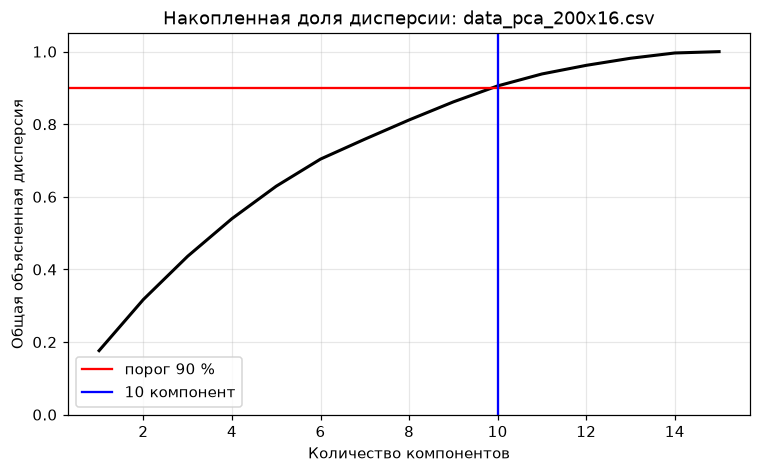

Новый фрейм главных компонент: (200, 11)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,y
0,-4.578847,3.848787,0.541379,0.634336,0.024733,0.638674,-0.531792,-0.752758,-0.955924,-1.841141,-0.47
1,-0.700449,0.149085,-2.766822,0.285838,-0.977398,2.389334,-0.062684,0.094682,-0.960747,-0.005511,0.99
2,0.316382,0.702997,0.772354,0.412586,0.317753,-1.752143,-0.720578,0.660028,1.072931,0.216519,1.36
3,0.309713,-0.183985,-0.359344,1.028388,0.085893,-0.639136,-0.468502,-1.770686,-1.007697,0.738025,1.43
4,-2.582146,-1.014980,0.194658,0.569724,0.605275,-0.102109,0.448854,0.847643,-0.507637,0.310599,1.03


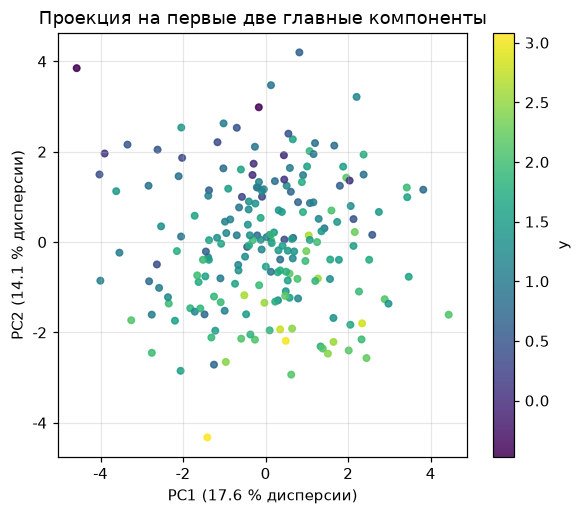

Линейная регрессия на тесте (25 % объектов):
  все 15 признаков:     R2=0.9482, MSE=0.0174, MAE=0.1051
  10 главных компонент: R2=0.4702, MSE=0.1775, MAE=0.3281


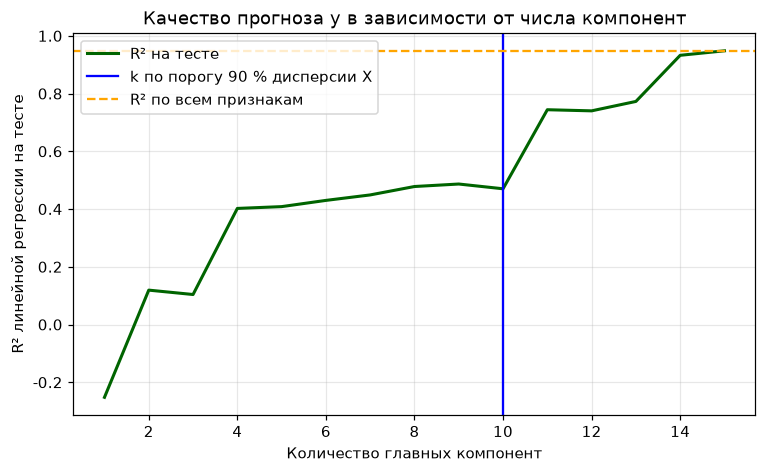

In [3]:
res_200 = analyze_dataset("data_pca_200x16.csv")


## 4. Набор 1000 × 51


Файл: data_pca_1000x51.csv
Размер (наблюдения × переменные): (1000, 51)
Столбцы: ['x1', 'x2', 'x3', 'x4', 'x5'] ... ['x49', 'x50', 'y']
Пропусков: 0
Признаков: 50, отклик y: min=-2.730, max=7.610, среднее=2.044, ст. откл.=1.523


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x42,x43,x44,x45,x46,x47,x48,x49,x50,y
0,4.33,-1.73,0.47,-9.52,3.21,0.74,22.71,-2.01,16.16,16.66,...,12.31,3.61,-6.57,-10.73,8.77,-0.25,-0.66,0.50,-2.16,-0.31
1,9.01,-1.25,0.54,-2.87,1.54,9.06,16.62,3.20,0.62,-1.94,...,-3.46,5.51,-0.29,2.11,2.26,-8.23,-1.28,-4.93,4.54,1.22
2,1.50,0.93,1.08,1.58,-9.84,-1.27,11.91,-2.91,-11.43,7.24,...,8.75,-0.36,1.54,-3.68,7.67,-0.34,0.54,-2.26,2.86,3.43
3,12.21,2.87,4.60,-9.51,-3.72,6.89,26.02,7.49,2.62,5.10,...,-4.76,8.51,-5.88,3.20,2.28,-8.47,-3.99,-2.91,8.62,3.61
4,0.37,-0.47,2.66,-7.90,1.82,1.12,20.53,2.80,18.65,9.90,...,-0.38,0.16,-0.55,-2.94,4.50,0.13,3.22,0.71,1.68,-0.44


Чтобы объяснить 90 % дисперсии, нужно 17 компонент (фактически объясняется 90.98 %).


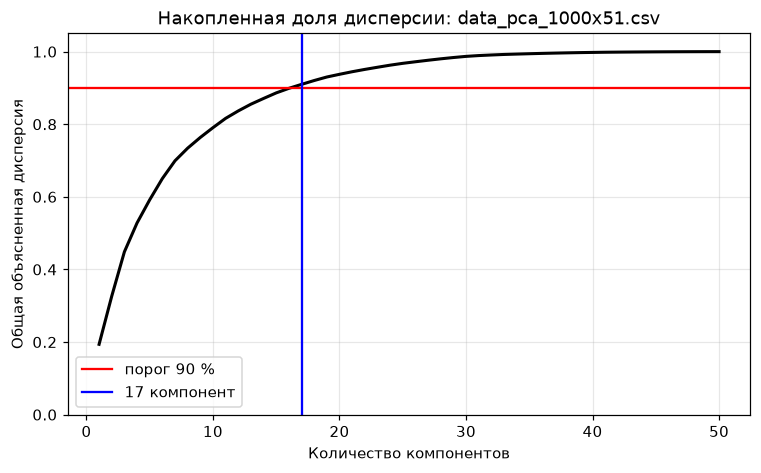

Новый фрейм главных компонент: (1000, 18)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,y
0,3.083222,4.153072,2.634989,-2.178678,1.037826,3.838159,-2.632911,1.934170,1.052812,-0.653429,-0.552170,0.418220,-0.350718,-1.227128,-1.306312,-1.475701,0.538322,-0.31
1,0.776257,-3.717443,-0.773840,-1.371159,-2.120160,0.092495,-1.070968,1.872333,0.980482,1.705579,-1.177698,-0.624081,1.007450,-0.738508,1.041961,-0.461887,-0.142664,1.22
2,-2.596997,1.377791,0.620273,-1.040821,-0.509576,0.537485,-1.043983,-2.928395,-1.501868,0.200804,-0.853771,-0.954658,3.462931,0.681295,-0.513450,0.119271,-0.837053,3.43
3,4.917645,-4.869668,-3.689803,-3.016056,-1.889658,1.322823,-1.129797,-0.422193,-0.599398,1.964579,0.823295,-0.280475,0.804656,0.697536,-0.041347,-0.991929,-0.687581,3.61
4,2.366881,-0.326867,1.036475,0.774125,1.573840,1.335071,0.675512,2.500407,0.741091,-1.746017,0.678801,0.164574,-0.753659,0.734214,-0.240094,-0.902614,-0.440474,-0.44


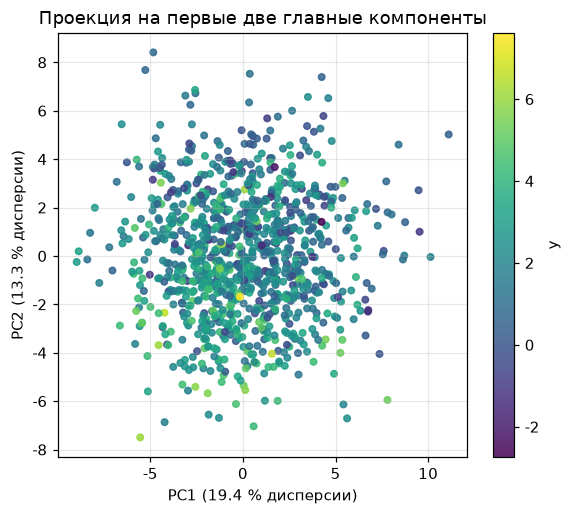

Линейная регрессия на тесте (25 % объектов):
  все 50 признаков:     R2=0.9588, MSE=0.0872, MAE=0.2365
  16 главных компонент: R2=0.6358, MSE=0.7706, MAE=0.6967


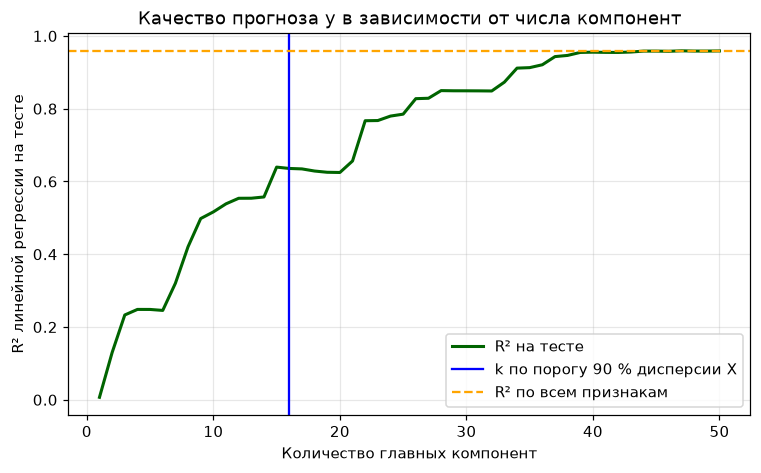

In [4]:
res_1000 = analyze_dataset("data_pca_1000x51.csv")


## 5. Набор 10 000 × 201


Файл: data_pca_10000x201.csv
Размер (наблюдения × переменные): (10000, 201)
Столбцы: ['x1', 'x2', 'x3', 'x4', 'x5'] ... ['x199', 'x200', 'y']
Пропусков: 0
Признаков: 200, отклик y: min=-176.720, max=213.650, среднее=30.289, ст. откл.=47.200


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x192,x193,x194,x195,x196,x197,x198,x199,x200,y
0,8.43,6.01,-2.72,0.72,4.21,-2.41,-13.92,-4.76,12.84,2.14,...,205.61,-31.02,-55.51,-107.07,86.04,-194.53,-248.93,-201.57,-128.54,-17.03
1,10.20,2.80,3.69,4.78,-11.03,-0.59,0.23,-1.41,-1.00,0.68,...,121.37,-148.39,68.38,-51.78,115.29,6.08,-126.89,-26.54,-25.07,33.54
2,0.65,2.16,-4.61,7.55,-15.61,-1.78,5.94,-10.31,6.04,-14.88,...,124.62,-56.07,-121.72,-39.61,95.11,-210.68,-184.60,294.36,-265.74,10.16
3,-2.55,-4.17,0.37,13.28,-0.99,4.19,6.62,-18.58,4.22,-14.80,...,339.98,-17.28,20.72,-196.00,154.71,-28.03,-382.79,80.13,-89.68,44.21
4,7.16,4.12,-12.33,4.42,-11.44,-0.41,-1.52,-6.19,-0.99,2.49,...,235.38,50.33,69.94,-88.98,133.11,-92.09,-263.55,531.99,-26.01,127.59


Чтобы объяснить 90 % дисперсии, нужно 24 компонент (фактически объясняется 90.12 %).


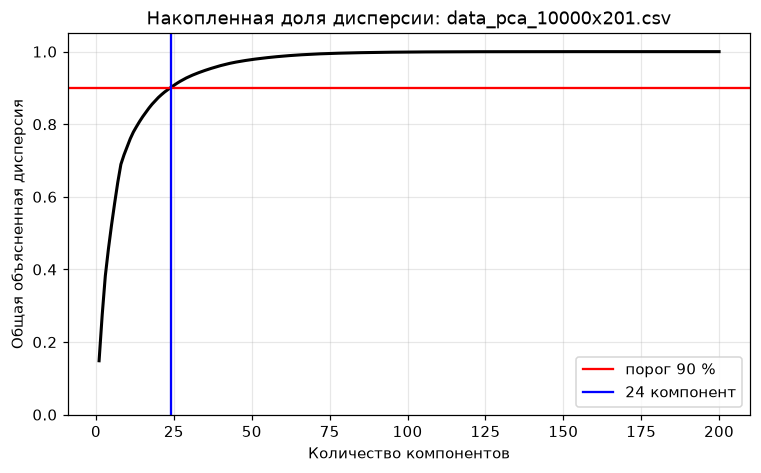

Новый фрейм главных компонент: (10000, 25)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,y
0,2.312342,-4.343625,-2.209974,-8.531923,0.978619,-0.867052,-1.398554,0.430619,-1.369017,-0.688906,...,0.886175,-1.817794,2.497114,1.600850,-0.291119,-1.170367,-0.002576,0.495603,0.364787,-17.03
1,-4.244069,-6.254199,0.407339,5.938669,4.501692,1.968256,1.465769,2.805888,1.938898,-0.256970,...,0.172993,-1.859390,-3.090526,-0.649563,0.775174,-0.074017,1.323207,-1.644289,-0.658557,33.54
2,5.907631,8.565359,-1.577746,-1.195535,-4.002604,3.144236,-7.954975,6.328073,1.860162,2.156286,...,-0.702645,0.107165,1.530556,1.171823,0.656133,1.234801,-0.390078,1.504531,1.431212,10.16
3,-3.660416,0.048263,8.366405,-0.644076,0.371795,2.021463,1.199234,-0.472782,-0.796051,-3.064776,...,0.936795,3.359623,-0.496329,-1.897744,0.609190,1.374838,-1.742424,0.186200,-0.233735,44.21
4,-1.799052,6.127590,3.790150,3.808245,4.391962,-2.631308,6.629835,1.424619,1.736419,0.419238,...,-0.557493,-0.690257,0.716937,1.469355,0.258860,-4.101168,-3.592981,0.084135,-1.341720,127.59


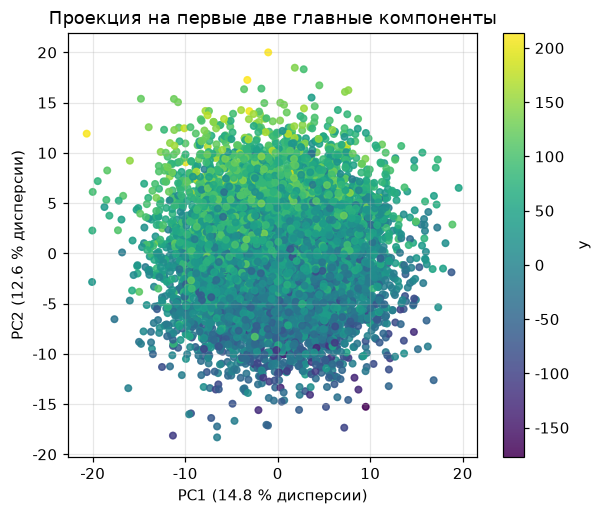

Линейная регрессия на тесте (25 % объектов):
  все 200 признаков:     R2=1.0000, MSE=0.0563, MAE=0.1841
  24 главных компонент: R2=0.9690, MSE=65.3910, MAE=6.4819


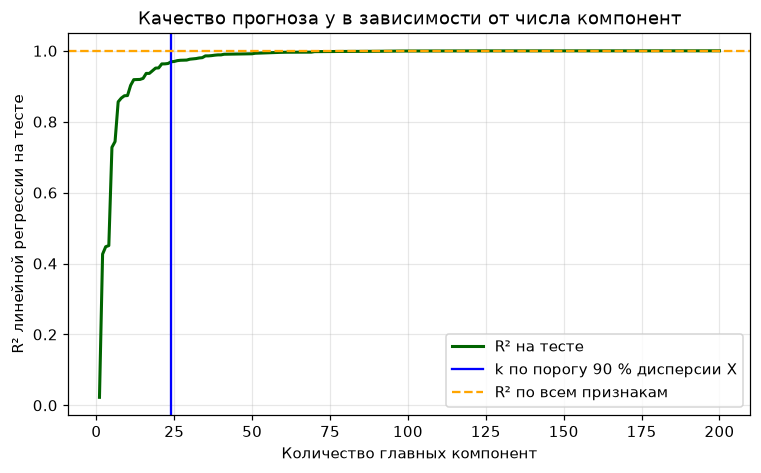

In [5]:
res_10000 = analyze_dataset("data_pca_10000x201.csv")


## 6. Сводная таблица результатов


In [6]:
rows = []
for res in (res_200, res_1000, res_10000):
    rows.append({
        "набор": "{} × {}".format(res["n_samples"], res["n_features"] + 1),
        "признаков": res["n_features"],
        "компонент для 90 % дисперсии": res["n_opt_full"],
        "доля дисперсии X": round(res["var_at_opt"], 4),
        "R² все признаки": round(res["scores_all"]["R2"], 4),
        "MSE все признаки": round(res["scores_all"]["MSE"], 4),
        "R² PCA 90 %": round(res["scores_pca"]["R2"], 4),
        "MSE PCA 90 %": round(res["scores_pca"]["MSE"], 4),
        "компонент на обучении": res["n_opt_train"],
    })

summary = pd.DataFrame(rows)
display(summary)


,набор,признаков,компонент для 90 % дисперсии,доля дисперсии X,R² все признаки,MSE все признаки,R² PCA 90 %,MSE PCA 90 %,компонент на обучении
0,200 × 16,15,10,0.9056,0.9482,0.0174,0.4702,0.1775,10
1,1000 × 51,50,17,0.9098,0.9588,0.0872,0.6358,0.7706,16
2,10000 × 201,200,24,0.9012,1.0000,0.0563,0.9690,65.3910,24


## Выводы

1. Все три файла успешно читаются в европейском формате (`sep=';'`, `decimal=','`), пропусков нет. В каждом наборе есть непрерывный столбец `y`, поэтому пункт 5 задания выполнен линейной регрессией, а не классификацией и не `KMeans` из черновика на слайде.

2. Перед PCA признаки стандартизованы. Оптимальное число компонент по аудиторному правилу «объяснить 90 % дисперсии X» оказывается заметно меньше исходной размерности:
   - 200 × 16: **10** компонент из 15 (около 90.6 % дисперсии);
   - 1000 × 51: **17** компонент из 50 (около 91.0 %);
   - 10 000 × 201: **24** компоненты из 200 (около 90.1 %).
   То есть данные сильно скоррелированы, и PCA сжимает их в несколько раз.

3. Линейная регрессия по **всем** исходным признакам описывает `y` очень хорошо: \(R^2\) около 0.95 на малом наборе, 0.96 на среднем и практически 1.00 на большом. Это похоже на то, что отклик почти линейно зависит от `x`.

4. Если оставить только компоненты, дающие 90 % дисперсии **признаков**, качество прогноза `y` падает: на наборе 200 × 16 \(R^2\) снижается примерно с 0.95 до 0.47, на 1000 × 51 — с 0.96 до 0.64. На наборе 10 000 × 201 \(R^2\) остаётся высоким (около 0.97), но MSE растёт на порядки (с ≈ 0.06 до ≈ 65), потому что у `y` там большая дисперсия, и «хвостовые» компоненты, почти невидимые в X, всё ещё нужны для точного прогноза.

5. График \(R^2\) от числа компонент это подтверждает: порог 90 % дисперсии X **не совпадает** с оптимумом для предсказания `y`. Для регрессии выгоднее брать больше компонент (или все). Практический вывод занятия: критерий «оставить 90 % дисперсии» удобен для сжатия и визуализации, но для последующей модели его нужно проверять по метрике самой задачи, а не только по спектру PCA.

6. Первые две главные компоненты даже на большом наборе объясняют лишь около 30 % дисперсии, поэтому двумерная проекция полезна как обзор, но не заменяет выбранный набор из 10–24 компонент, который сохраняется в новом фрейме (`PC1`, `PC2`, … и столбец `y`).
